# Урок 14. Кто закрывает пиксель

[План курса](../../README_ru.md)

Красное горизонтальное пятно и синее вертикальное висят на одной линии взгляда. Камера видит крест. На пересечении два пятна попали в один пиксель, хотя в пространстве между ними целая единица. От цвета этого пикселя и пойдём обратно к устройству рендера.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo

## Два порядка, одна камера

Слева камера рисует ближнее пятно первым. Справа те же цвета и формы проходят в обратном порядке. При взгляде спереди пересечение слева краснее. Сбоку пятна расходятся, и кадры почти совпадают. Если повернуть камеру достаточно далеко за сцену, передним станет синее.

Угол движет камеру по окружности вокруг точки $(0,0,4)$. Другой регулятор двигает само красное пятно вдоль мировой оси $Z$. Поле $u$ выбирает столбец на средней строке. Отключение одного пятна оставляет одинаковую картинку с обеих сторон.

In [2]:
display(demo.experiment(14, "ru"))

## От трёх координат к участию в пикселе

Кадр имеет размер $65\times65$. Номера столбцов и строк идут от 0 до 64. При нулевом угле камера находится в начале мира, смотрит вдоль $+Z$, а середина кадра приходится на $(32,32)$. Центры $(0,0,3.5)$ и $(0,0,4.5)$ оба попадают туда. Меньшая **глубина в координатах этой камеры** означает ближнее пятно. При повороте камеры глубины вычисляются заново.

Глубина задаёт порядок. Форму следа задаёт матрица из прошлого урока. У красного пятна горизонтальный масштаб в мире $0.55$, глубина $3.5$, фокус $48$ пикселей. Масштаб на экране равен $48\cdot0.55/3.5=7.543$ пикселя. По вертикали получим $48\cdot0.35/3.5=4.8$. Здесь оси совпали с осями кадра, поэтому горизонтальный и вертикальный расчёты можно разнести.

В шести пикселях правее центра горизонтальное смещение равно $6/7.543\approx0.795$ собственных ширин. Вертикальное равно нулю. Квадрат расстояния в единицах пятна $q\approx0.795^2=0.633$. Вес $G=\exp(-q/2)\approx0.729$. Центральная непрозрачность красного $o=0.6$ безразмерна. Только доля $\alpha=oG\approx0.437$ приходится на красное в этом пикселе. В центре $q=0$, вес равен единице и $\alpha=o$.

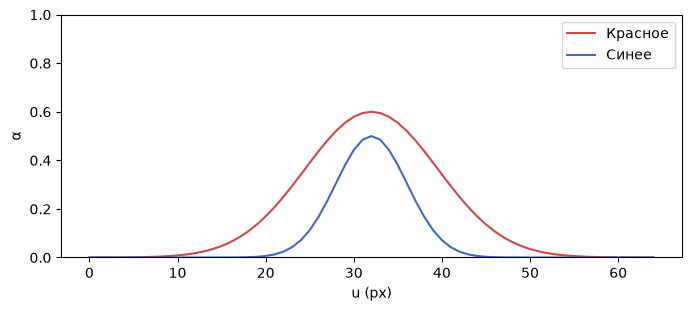

In [3]:
fig = demo.visibility_profile("ru")
display(fig)
plt.close(fig)

## Сколько пикселя ещё свободно

Пока сцена пуста, свободна единица. Обозначим её $T$, от transmittance, доля, пропускаемая предыдущими слоями. У красного в центре $\alpha_1=0.6$. Вклад красного $1\cdot0.6=0.6$. Дальше проходит $T=1\cdot(1-0.6)=0.4$. Синее пятно с $\alpha_2=0.5$ забирает половину остатка, $0.4\cdot0.5=0.2$. Ещё $0.4\cdot(1-0.5)=0.2$ достаётся белому фону.

У красного тройка $(1,0,0)$, у синего $(0,0,1)$, у белого $(1,1,1)$. Каждая компонента от 0 до 1. Сначала умножаем все три компоненты на долю слоя, затем складываем по каналам.

$$
C=0.6(1,0,0)+0.2(0,0,1)+0.2(1,1,1)=(0.8,0.2,0.4).
$$

От перестановки свободному фону останется столько же. Синее теперь забирает $0.5$ первым, красному достаётся $(1-0.5)0.6=0.3$. Итог $(0.5,0.2,0.7)$. Почти весь эффект заметен там, где обе величины $\alpha$ велики.

In [4]:
scene, camera = sr.overlap_scene(), sr.orbit_camera()
for u in (32, 38):
    remaining = 1.
    rgb = np.zeros(3)
    for item in sr.project_splats(scene, camera, 65, 65):
        alpha = sr.footprint_alpha([u, 32], item)
        rgb += remaining * alpha * item["color"]
        remaining *= 1 - alpha
    rgb += remaining * np.ones(3)
    np.testing.assert_allclose(rgb, sr.render_scene(scene, camera)[32, u])
    print(u, np.round(rgb, 6))

32 [0.8 0.2 0.4]
38 [0.905928 0.468656 0.562728]


## Из цикла получается целый кадр

Для пикселя $p=(u,v)$ сначала накапливаем чёрный ноль $C=(0,0,0)$ и оставляем $T=1$. На каждом пятне $i$ прибавляем $T\alpha_i c_i$ к цвету $C$, после чего заменяем $T$ на $T(1-\alpha_i)$. В конце прибавляем $T c_{\rm bg}$, где $c_{\rm bg}$ — RGB фона. Первая буква $C$ относится к кадру, маленькая $c_i$ — к одному пятну.

У наклонённого эллипса вместо двух отдельных делений работает $q=\delta^\mathsf{T} S^{-1}\delta$. Здесь $\delta=p-m$ — смещение от экранного центра $m$ в пикселях, $S$ — экранная ковариация в квадратных пикселях, $S^{-1}$ — её обратная. Сначала матрица умножает вектор из двух смещений, затем скалярное произведение с тем же смещением даёт одно число без единиц. В коде из него снова получается $\alpha_i=o_i\exp(-q/2)$.

Камера отбрасывает центры с глубиной не больше $0.05$, иначе деление на глубину при проекции теряет смысл для этой камеры. Все оставшиеся центры сортируются один раз на кадр. Два длинных пересекающихся эллипсоида могут иметь разный передний край на разных лучах. Сортировка по центрам присвоит им один порядок во всём кадре. При почти равных глубинах смена порядка иногда даёт заметный скачок цвета.

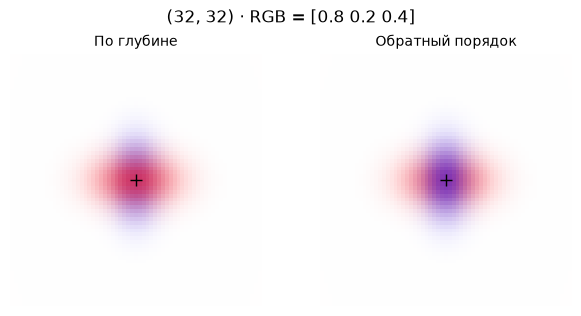

In [5]:
fig = demo.visibility_figure("ru")
display(fig)
plt.close(fig)

## Опыты и разбор

Как изменится центральный пиксель, если синее пятно исчезнет? В каком ракурсе перестановка почти незаметна?

<details><summary>Разбор</summary>

При $\alpha_2=0$ остаются $0.6(1,0,0)+0.4(1,1,1)=(1,0.4,0.4)$. Сбоку у двух следов почти нет общей площади. В любой точке один из множителей $\alpha_1\alpha_2$ тогда мал. Разность между порядками равна $\alpha_1\alpha_2(c_1-c_2)$, что в центре исходного примера даёт $0.3(1,0,-1)$.

</details>